# Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

# Playing around with QnRLv2

In [3]:
# # Load config from file.
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-13.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-12.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-11.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-10.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-9.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-8.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-7.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-6.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-5.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-0.py")
# module = qnrl.tools.load_python_module_from_filepath(cfg_path)
# config = module.config

from qnrl.algorithms.qnrl_v2 import QnRL_v2
from qnrl.optimizer import *
from qnrl.gym import *
from qnrl.modules import *


# CartPole-v1
din = 4
n_actions = 2

n_returns = 2**5
# n_returns = 101
z_min = -100
z_max = 100
m_moment = 1
n_reuploads = 2
n_layers = 5
# diff_method="backprop"
# shots=None
diff_method=None
shots=100
seed = 0
# seed = 42

# Experiment configuration.
config = QnRL_v2(
    buffer_size=10_000,
    seed=seed,
    batch_size=128,
    # total_timesteps=500_000,
    total_timesteps=20_000,
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5,
    #
    env=ScaleObservation(
        env=EnvConfig(env_id="CartPole-v1"),
        scale=[2.4, 2.5, 0.21, 2.5],
    ),
    model=QuantumNativeQNetworkSplit_v3(
        din=din,
        n_actions=n_actions,
        n_returns=n_returns,
        z_min=z_min,
        z_max=z_max,
        m_moment=m_moment,
        n_reuploads=n_reuploads,
        n_layers=n_layers,
        diff_method=diff_method,
        shots=shots,
        rngs_kwargs=dict(default=seed),
    ),
    optimizer=Adam(learning_rate=1.0e-3),
    # optimizer=Adam(learning_rate=1.0e-2),
    # optimizer=Adam(learning_rate=25e-5),
    # optimizer=Partition(
    #     transforms={
    #         'key_circuit_weights': Adam(learning_rate=1.0e-2),
    #         # 'key_circuit_weights': Adam(learning_rate=1.0e-3),
    #         # 'key_layer_project_input': Adam(learning_rate=1.0e-3),
    #         'key_layer_project_input': Adam(learning_rate=1.0e-1),
    #     },
    #     pytree={
    #         'circ_weights': 'key_circuit_weights',
    #         'layer_project_input': {
    #             'bias': 'key_layer_project_input',
    #             'kernel': 'key_layer_project_input',
    #         },
    #     },
    # ),
    # policy_type='phased_stochastic_greedy',
    policy_type='greedy',
    target_type='stochastic',
    # target_type='greedy',
)

In [4]:
# env = config.env.make()
# obs, _ = env.reset()
# action_pmf = config.model.call_gen_action_dist(obs)
# rho = config.model.call_return_density_matrix(obs, action_pmf)

In [5]:
history_list = config.train()
history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)

  0%|          | 0/20000 [00:00<?, ?step/s]/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
100%|██████████| 20000/20000 [06:56<00:00, 47.97step/s, episode_step=19917, episode_reward=139, episode_length=139, episode_time=5.35, loss_step=2e+4, loss=0.1438678911618425]  


Text(0, 0.5, 'episode_reward')

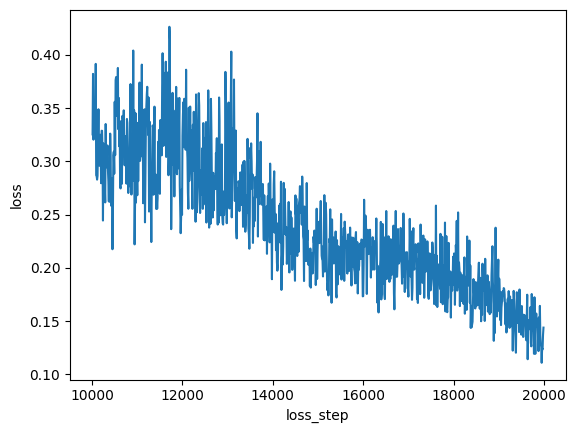

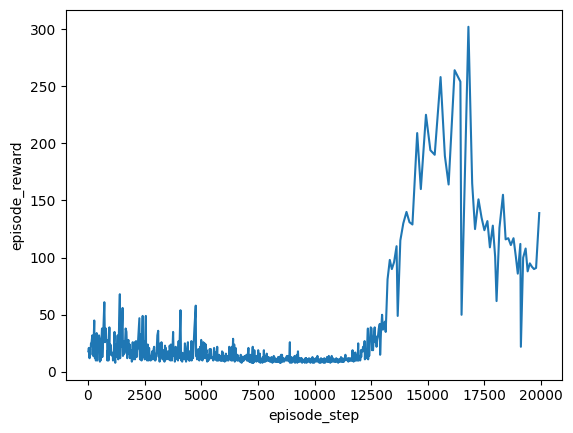

In [6]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(history_dict['loss_step'], history_dict['loss'])
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

In [ ]:
config.eval()

In [7]:
history_list[-10:]

[{'loss_step': 15030, 'loss': Array(0.00027936, dtype=float64)},
 {'episode_step': 15032,
  'episode_reward': 21.0,
  'episode_length': 21,
  'episode_time': 0.644733},
 {'loss_step': 15040, 'loss': Array(0.00019359, dtype=float64)},
 {'episode_step': 15046,
  'episode_reward': 13.0,
  'episode_length': 13,
  'episode_time': 0.330713},
 {'loss_step': 15050, 'loss': Array(0.00016706, dtype=float64)},
 {'loss_step': 15060, 'loss': Array(0.00015039, dtype=float64)},
 {'loss_step': 15070, 'loss': Array(0.00017925, dtype=float64)},
 {'episode_step': 15078,
  'episode_reward': 31.0,
  'episode_length': 31,
  'episode_time': 0.949998},
 {'loss_step': 15080, 'loss': Array(0.00012864, dtype=float64)},
 {'loss_step': 15090, 'loss': Array(0.00014063, dtype=float64)}]

In [24]:
def is_unitary(m: jnp.ndarray):
    return jnp.allclose(jnp.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: jnp.ndarray):
    return jnp.allclose(m, m.T.conj())

In [30]:
from qnrl.algorithms.qnrl_v2 import *

model_policy: QuantumNativeQNetworkSplit_v3 = config.model
graphdef, state = nnx.split(model_policy)
model_target = nnx.merge(graphdef, state)

env = config.env.make()
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).


# observation, _ = env.reset()

# Generate some random observations.
batch_size = 3
observations = jnp.array([env.reset()[0] for _ in range(batch_size)])
next_observations = jnp.array([env.reset()[0] for _ in range(batch_size)])

# # Ensure batched.
# observation = jnp.reshape(observation, (-1, model.din))

# Test creating rho.
target_action_pmfs = model_target.call_gen_action_dist(next_observations)
target_actions = jnp.argmax(target_action_pmfs, axis=-1) # (batch,)
target_actions_onehot = nnx.one_hot(target_actions, num_classes=model_target.n_actions) # PMF for greedy action.
target_return_pmfs = model_target.call_gen_return_dist_NEW(next_observations, target_actions_onehot) # (batch_size,n_atoms)
psi = jnp.sqrt(target_return_pmfs) # (batch,d_returns,) State vector representation of target return-atom PMFs.
rho = nnx.vmap(density_matrix)(psi) # (batch,2**d_returns,2**d_returns,) Density matrix (i.e., Hermitian core) representation of target return-atom. We need this to be batched, so also create a batched variant of `density_matrix` using `nnx.vmap`.

# Get output from policy model.
policy_action_pmfs = model_policy.call_gen_action_dist(observations) # (batch,n_actions,)


# print(f"{target_action_pmfs.shape = }")
# print(f"{target_actions.shape = }")
# print(f"{target_actions_onehot.shape = }")
# print(f"{target_return_pmfs.shape = }")
# print(f"{psi.shape = }")
# print(f"{rho.shape = }")
# print(f"{is_hermitian(rho) = }")
# print(f"{is_unitary(rho) = }")
print(f"{observations.shape = }")
# print(f"{policy_action_pmfs.shape = }")

model_policy.call_hermitian_loss(observations, policy_action_pmfs, rho)

# # Must project the observations into a space ingestible for the quantum circuit.
# circuit_inputs = model.layer_project_input(observation)
# circuit_inputs = jnp.reshape(circuit_inputs, (-1, *model.circ_inputs_shape,)) # (batch,d_returns,1,)
# device = qml.device('default.qubit', shots=None)
# qnode = qml.QNode(func=circuit_hermitian_loss, device=device, interface="jax", diff_method='backprop')
# qnode_vmap = nnx.vmap(
#     f=qnode,
#     in_axes=(0, 0, None, None, None, None, None, 0),
#     out_axes=0,
# )
# qnode_vmap(
#     inputs=circuit_inputs,
#     probs_actions=policy_action_pmfs,
#     weights=model.circ_weights,
#     n_actions=model.n_actions,
#     d_actions=model.d_actions,
#     d_returns=model.d_returns,
#     n_layers=model.n_layers,
#     rho=rho,
# )

# for t in range(500):
#     action_pmf = model.call_gen_action_dist(observation)
#     action = action_pmf.argmax().item()
    
#     return_pmf = model.call_gen_return_dist_NEW(observation, action_pmf).squeeze()
    
#     next_observation, reward, done, truncation, info = env.step(action)
    
    
#     # print(f"{observation = }")
#     # print(f"{action_pmf = }")
#     # print(f"{action = }")
#     # print(f"{return_pmf = }")
#     # print(f"{return_pmf.sum() = }")
#     # print()
    
#     # # Plot the returns PMF.
#     # plt.figure(figsize=(14,8))
#     # x = jnp.arange(len(return_pmf))
#     # plt.bar(x, return_pmf)
#     # plt.xticks(x, [f"{i:0{model.d_returns}b}"[::-1] + f" : z{i}" for i in range(model.n_returns)], rotation=90)
#     # plt.xlabel("State index (binary) : Return atom")
#     # plt.show()
    
#     observation = next_observation.copy()
    
#     if done:
#         break
# print(info)

observations.shape = (3, 4)


Array([0.04498759, 0.04825535, 0.05457702], dtype=float64)

In [26]:
# qnrl.algorithms.qnrl_v2.circuit_return_dist(None, None, None, None, None, None, None, 1, 5, None)

# Compare return PMF distributions

## QnRL

In [35]:
# Load config from file.
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-13.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-12.py")
cfg_path = Path("./experiments/qnrl_CartPole-v1_config-11.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-10.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-9.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-8.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-7.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-6.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-5.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-0.py")
module = qnrl.tools.load_python_module_from_filepath(cfg_path)
config = module.config

nnx.display(config)

In [36]:
model: qnrl.modules.QuantumNativeQNetworkSplit = config.model
checkpoint_manager = config.checkpoint.make()
step_to_restore = checkpoint_manager.latest_step()
if step_to_restore is not None:
    model = qnrl.tools.restore_model_from_checkpointmanager(model, checkpoint_manager)
    print(f"Restored model from step: {step_to_restore}")

env = config.env.make()
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).


observation, _ = env.reset()

history = []
for t in range(500):
    action_pmf = model.call_gen_action_dist(observation)
    action = action_pmf.argmax().item()
    
    return_pmf = model.call_gen_return_dist_NEW(observation, action_pmf).squeeze()
    
    history.append({
        'step': t,
        'action_pmf': action_pmf.squeeze(),
        'action': action,
        'return_pmf': return_pmf,
        'observation': observation,
    })
    
    next_observation, reward, done, truncation, info = env.step(action)
    
    
    # print(f"{observation = }")
    # print(f"{action_pmf = }")
    # print(f"{action = }")
    # print(f"{return_pmf = }")
    # print(f"{return_pmf.sum() = }")
    # print()
    
    # # Plot the returns PMF.
    # plt.figure(figsize=(14,8))
    # x = jnp.arange(len(return_pmf))
    # plt.bar(x, return_pmf)
    # plt.xticks(x, [f"{i:0{model.d_returns}b}"[::-1] + f" : z{i}" for i in range(model.n_returns)], rotation=90)
    # plt.xlabel("State index (binary) : Return atom")
    # plt.show()
    
    observation = next_observation.copy()
    
    if done:
        break
print(info)

Restored model from step: 499990
{'episode': {'r': 14.0, 'l': 14, 't': 0.101854}}


/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/orbax/checkpoint/_src/serialization/type_handlers.py:1269: UserWarning: Sharding info not provided when restoring. Populating sharding info from sharding file. Please note restoration time will be slightly increased due to reading from file. Note also that this option is unsafe when restoring on a different topology than the checkpoint was saved with.
  warnings.warn(


0.04427185967699771
0.06268060061387029


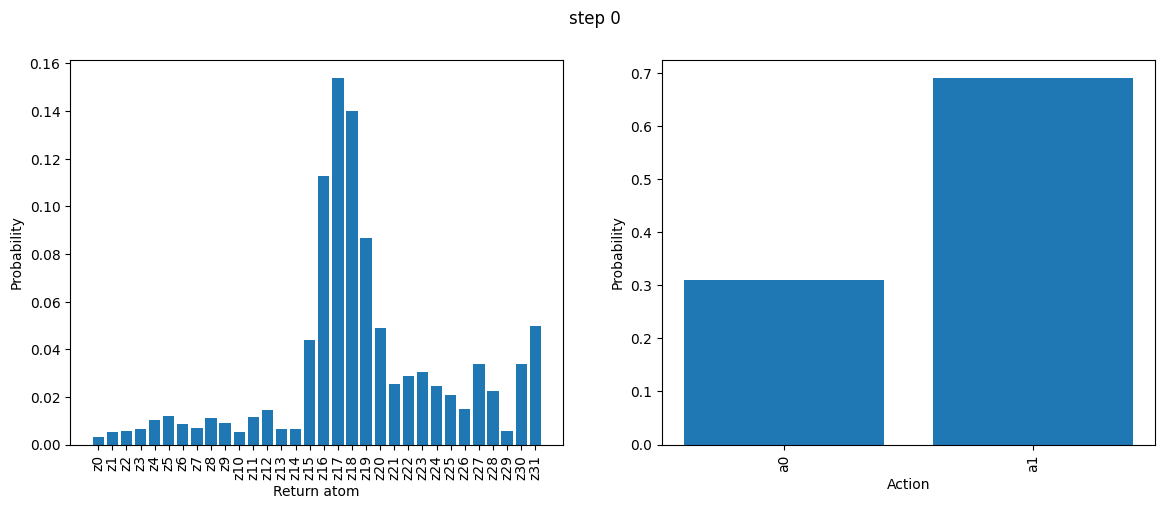

<Figure size 640x480 with 0 Axes>

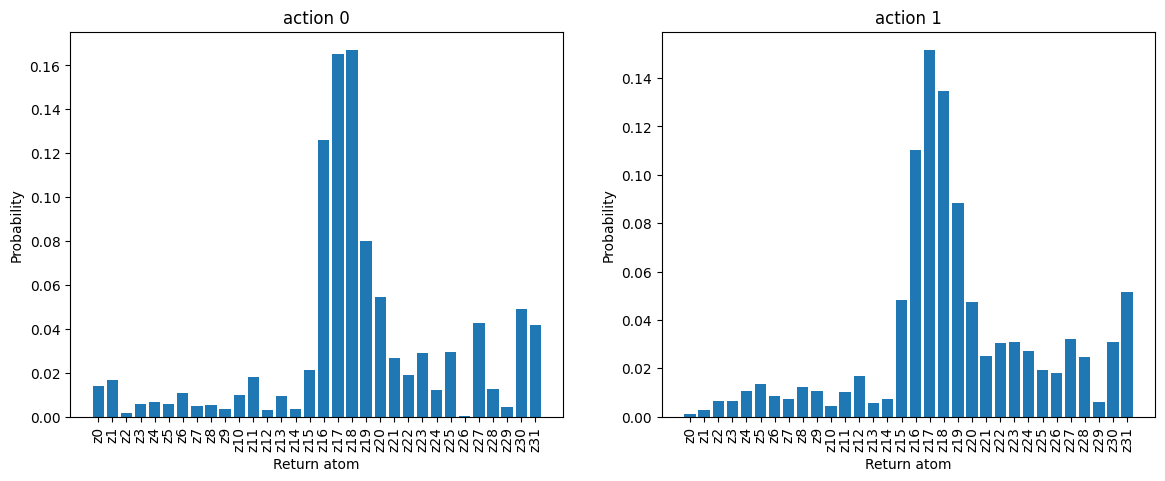

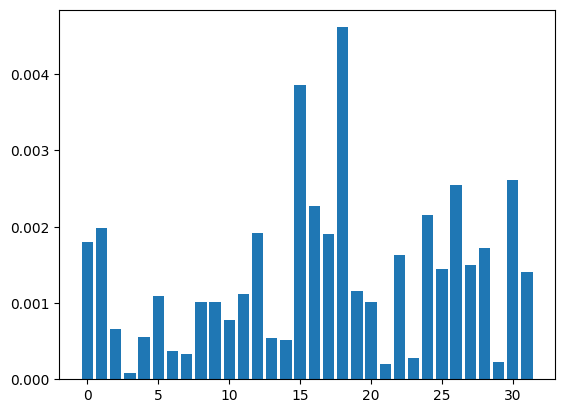

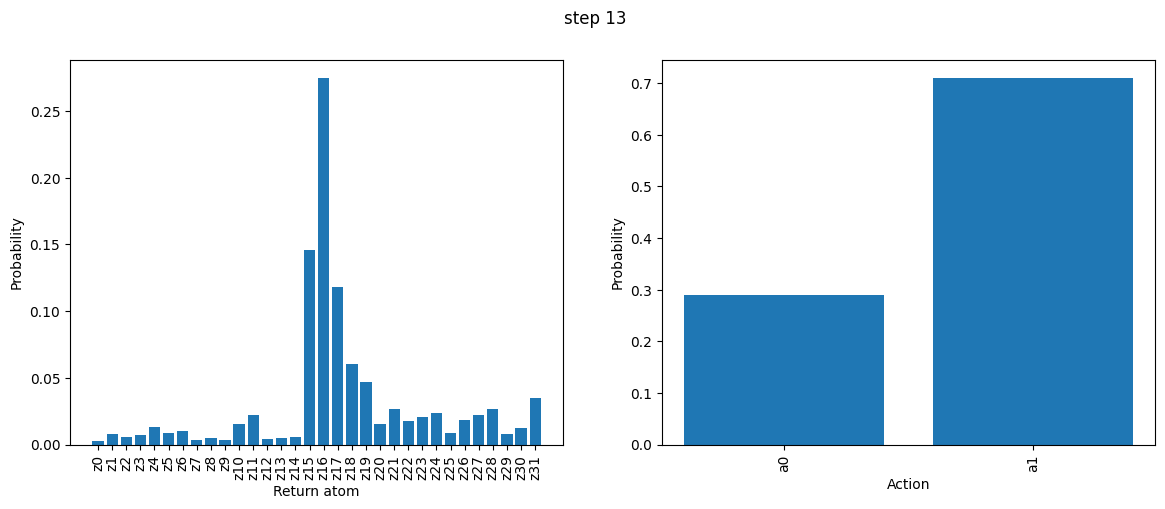

<Figure size 640x480 with 0 Axes>

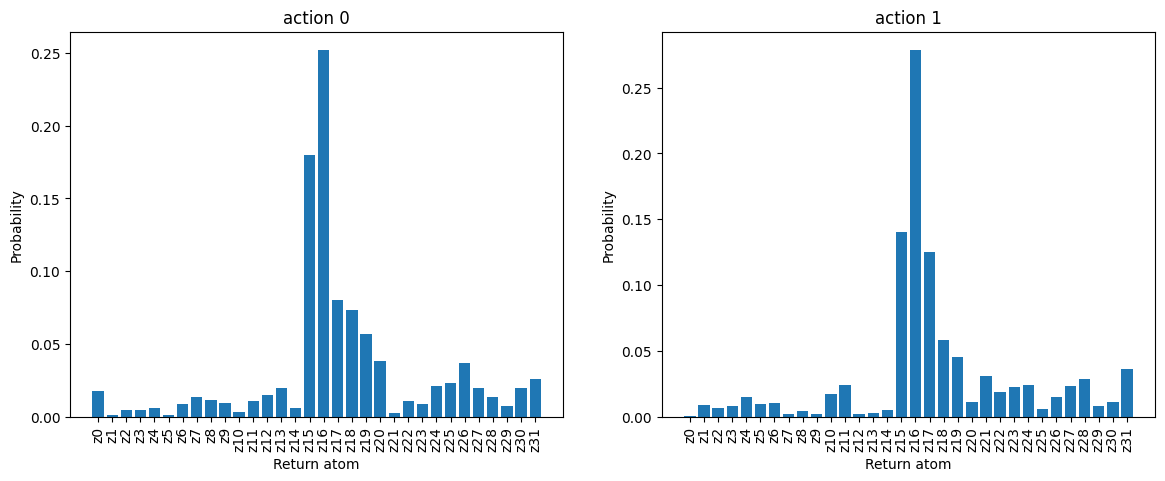

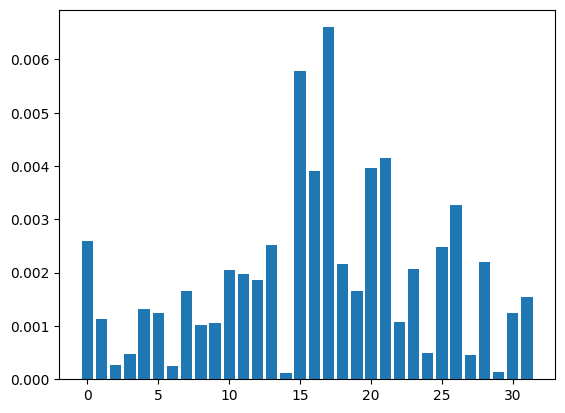

In [37]:
# Plot the returns PMF.
# for t, d in enumerate(history[:5]):
for _, d in enumerate([history[0], history[-1]]):
    fig, axs = plt.subplots(1,2, figsize=(14,5))
    x = jnp.arange(d['return_pmf'].shape[-1])
    axs[0].bar(x, d['return_pmf'])
    axs[0].set_xticks(x, [f"z{i}" for i in range(len(x))], rotation=90)
    axs[0].set_xlabel("Return atom")
    axs[0].set_ylabel("Probability")
    x = jnp.arange(d['action_pmf'].shape[-1])
    axs[1].bar(x, d['action_pmf'])
    axs[1].set_xticks(x, [f"a{i}" for i in range(len(x))], rotation=90)
    axs[1].set_xlabel("Action")
    axs[1].set_ylabel("Probability")
    # fig.show()
    fig.suptitle(f"step {d['step']}")
    
    
    # Plot the return PMF for each action individually.
    n_returns = d['return_pmf'].shape[-1]
    x = jnp.arange(n_returns)
    n_actions = 2
    plt.figure()
    # d_action = int(jnp.ceil(jnp.sqrt(n_actions)))
    # fig, axs = plt.subplots(d_action, d_action)
    fig, axs = plt.subplots(1, 2, figsize=(14,5))
    axs = axs.flatten()
    individual_return_pmf = []
    for a in range(n_actions):
        actions_onehot = nnx.one_hot(a, num_classes=n_actions)
        return_pmf = model.call_gen_return_dist_NEW(d['observation'], actions_onehot[None,:]).squeeze()
        axs[a].bar(jnp.arange(n_returns), return_pmf)
        axs[a].set_xticks(x, [f"z{i}" for i in range(len(x))], rotation=90)
        axs[a].set_title(f"action {a}")
        axs[a].set_xlabel("Return atom")
        axs[a].set_ylabel("Probability")
        individual_return_pmf.append(return_pmf)
    individual_return_pmf = jnp.array(individual_return_pmf)


    weighted_return_pmf = (individual_return_pmf * d['action_pmf'][:,None]).sum(axis=0)
    plt.figure()
    # plt.bar(jnp.arange(n_returns), weighted_return_pmf)
    plt.bar(jnp.arange(n_returns), jnp.abs(weighted_return_pmf - d['return_pmf']))
    print(jnp.abs(weighted_return_pmf - d['return_pmf']).sum())

In [38]:
nnx.display(model.U_atoms)

## C51 baseline

In [7]:
cfg_path = Path("./experiments/c51_CartPole-v1_config-0.py")
module = qnrl.tools.load_python_module_from_filepath(cfg_path)
config = module.config

nnx.display(config)

In [8]:
checkpoint_manager = config.checkpoint.make()
step_to_restore = checkpoint_manager.latest_step()
model: qnrl.modules.Sequential = config.model
if step_to_restore is not None:
    model = qnrl.tools.restore_model_from_checkpointmanager(model, checkpoint_manager)
    print(f"Restored model from step: {step_to_restore}")

atoms = jnp.linspace(start=config.z_min, stop=config.z_max, num=config.num_atoms)


env = config.env.make()
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).


observation, _ = env.reset()


history = []
for t in range(500):
    return_pmfs = model(observation).squeeze()
    q_vals = jnp.sum(return_pmfs * atoms, axis=-1)
    action = jnp.argmax(q_vals, axis=-1).item()
    
    
    history.append({
        'step': t,
        'return_pmfs': return_pmfs,
        'q_vals': q_vals,
        'action': action,
    })
    
    next_observation, reward, done, truncation, info = env.step(action)
    # print(f"{observation = }")
    # print(f"{q_vals = }")
    # print(f"{q_vals - q_vals.min() = }")
    # print(f"{q_vals/q_vals.sum() = }")
    # print(f"{action = }")
    # print()
    
    observation = next_observation.copy()
    
    if done:
        break

print(info)

/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/orbax/checkpoint/_src/serialization/type_handlers.py:1269: UserWarning: Sharding info not provided when restoring. Populating sharding info from sharding file. Please note restoration time will be slightly increased due to reading from file. Note also that this option is unsafe when restoring on a different topology than the checkpoint was saved with.
  warnings.warn(


Restored model from step: 499990
{'episode': {'r': 500.0, 'l': 500, 't': 0.333513}}


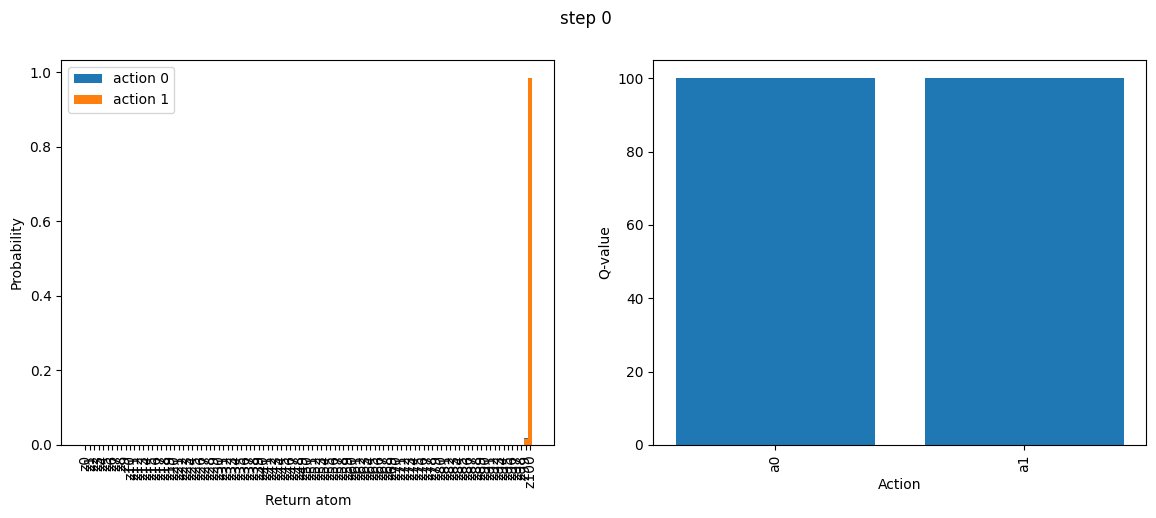

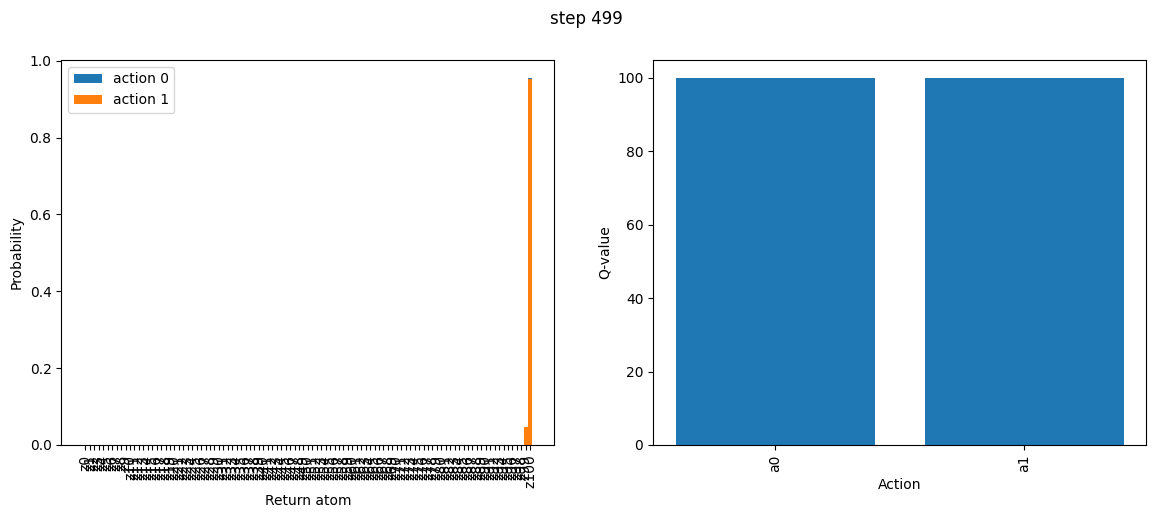

In [9]:
# Plot the returns PMF.
# for t, d in enumerate(history[:5]):
for t, d in enumerate([history[0], history[-1]]):
    fig, axs = plt.subplots(1,2, figsize=(14,5))
    x = jnp.arange(d['return_pmfs'].shape[-1])
    for a in range(d['return_pmfs'].shape[0]):
        axs[0].bar(x, d['return_pmfs'][a], label=f"action {a}")
    axs[0].set_xticks(x, [f"z{i}" for i in range(len(x))], rotation=90)
    axs[0].set_xlabel("Return atom")
    axs[0].set_ylabel("Probability")
    axs[0].legend()
    x = jnp.arange(d['q_vals'].shape[-1])
    axs[1].bar(x, d['q_vals'])
    axs[1].set_xticks(x, [f"a{i}" for i in range(len(x))], rotation=90)
    axs[1].set_xlabel("Action")
    axs[1].set_ylabel("Q-value")
    # fig.show()
    fig.suptitle(f"step {d['step']}")